# Particle sets and their potential

Run all cells. Change `rho`, `phase` or `show_ids` below and run again.
The plots show **initial positions**, without integrating trajectories.

- **48 particles:** the original set (40 star points and 8 probes).
- **84 particles:** the original set plus 36 neighboring points.
- **8 candidate chaotic particles:** historical IDs 3, 6, 7, 9, 12, 16, 21 and 23. Their chaotic character has not been verified for the reflected potential.
- **8 periodic particles:** IDs 85–92, with distinct numerically verified minimum periods of 5–12 forcing cycles at `rho = 0.30`. Changing `rho` displays the same initial positions but does not preserve this periodicity claim.

All panels use the main campaign's **reflected, gyroaveraged potential**, with magnetic field 1.5 T, constant field 0 and temporal mode 15 from `PHI_2.h5`. The displayed square is $[0,1]^2$; the spatial extension has period 2 and does not confine trajectories to this square.

In [1]:
rho = 0.30        # Campaign radius parameter: 0.00, 0.05, ..., 0.50.
phase = 0.0       # Fraction of one forcing cycle, from 0 to 1.
show_ids = False  # Set True to label particles with their original IDs.

In [2]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

# Works when launched from the repository root or its notebooks directory.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/potential/potential.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the GC2D_codigo repository.")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from dynamics.gc import GuidingCenterDynamics
from studies.main_campaign import RHOS, SOURCE_SHA256, load_field

# Each dataset is read from its own independent JSON file.
files = ["original_48.json", "expanded_84.json",
         "chaotic_candidates_8.json", "periodic_8.json"]
datasets = [json.loads((root / "data/particles" / name).read_text()) for name in files]
for dataset in datasets:
    assert dataset["source_sha256"] == SOURCE_SHA256
    assert len(dataset["particles"]) == dataset["particle_count"]
    expected_count = 0 if dataset["status"] == "pending" else dataset["target_particle_count"]
    assert dataset["particle_count"] == expected_count

field = load_field(root / "data/potential/V1/PHI_2.h5")  # Verifies SHA-256.
metadata = field.metadata
if not any(np.isclose(rho, value, rtol=0, atol=1e-12) for value in RHOS):
    raise ValueError("Choose rho from 0.00 to 0.50 in steps of 0.05.")
if not 0 <= phase <= 1:
    raise ValueError("Choose a phase between 0 and 1.")

# Convert the study's rho to meters, then to normalized cell coordinates.
rho_m = rho * 0.06 / (2 * np.pi)
dynamics = GuidingCenterDynamics(field, rho=rho_m / metadata.spatial_scale, B=1.5)
hamiltonian = dynamics.hamiltonian_potential
period = 1 / float(field.frequencies[0])
origin_m = np.array([metadata.source_x[0], metadata.source_y[0]])

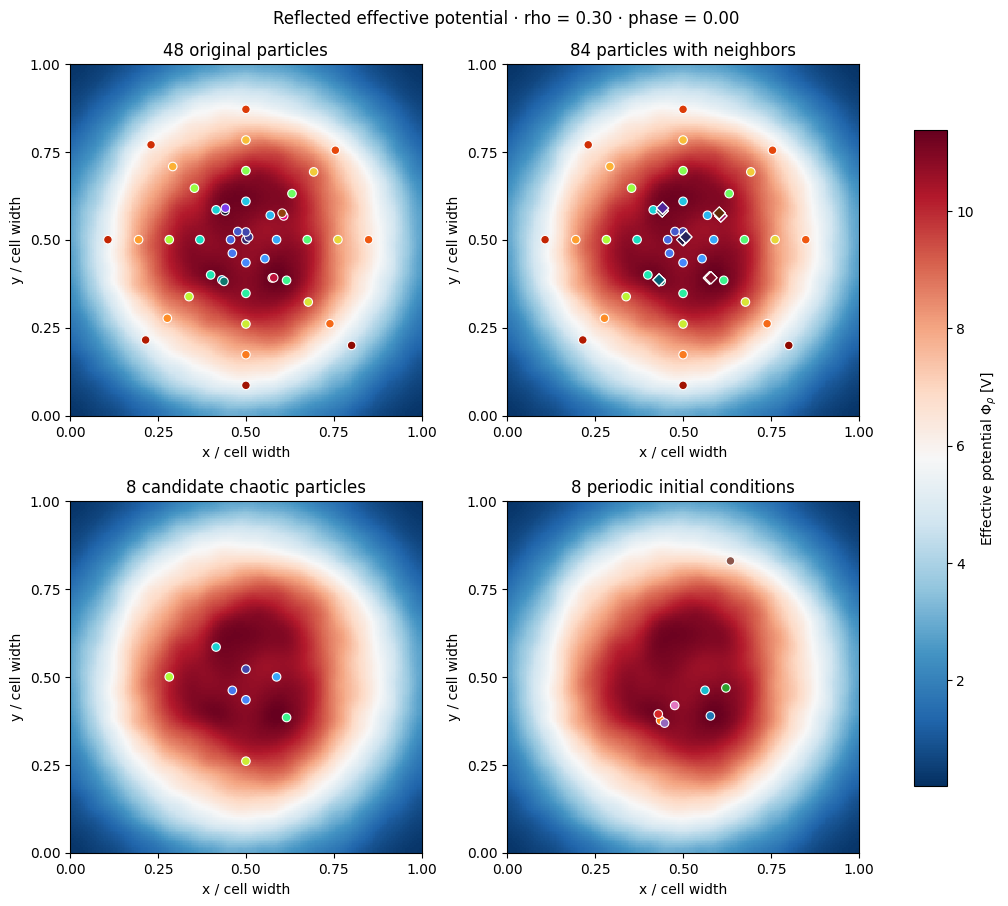

In [3]:
axis = np.linspace(0, 1, 201)
x, y = np.meshgrid(axis, axis)

# H = T * Phi_rho / (B * L**2); recover the effective potential in volts.
voltage_scale = dynamics.B * metadata.spatial_scale**2 / metadata.time_scale

def potential_at(cycle_phase):
    return voltage_scale * hamiltonian.evaluate(cycle_phase * period, x, y)

potential = potential_at(phase)
# Fixed color limits over the complete cycle (one temporal Fourier mode).
p0, p25, p50 = (potential_at(p) for p in (0, 0.25, 0.5))
mean = (p0 + p50) / 2
amplitude = np.hypot((p0 - p50) / 2, p25 - mean)
vmin, vmax = float(np.min(mean - amplitude)), float(np.max(mean + amplitude))
np.testing.assert_allclose(potential_at(1), p0, rtol=1e-11, atol=1e-12)

fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for ax, dataset in zip(axes.flat, datasets):
    particles = dataset["particles"]
    ids = np.array([p["id"] for p in particles])
    positions_m = np.array([p["position_m"] for p in particles]).reshape(-1, 2)
    xy = (positions_m - origin_m) / metadata.spatial_scale
    colors = np.array([p["color"] for p in particles])
    neighbors = np.array([p.get("kind") == "neighbor" for p in particles], dtype=bool)
    # Historical cell widths differ by rounding; physical positions remain exact.
    fractions = np.array([p["cell_fraction"] for p in particles]).reshape(-1, 2)
    np.testing.assert_allclose(xy, fractions, rtol=0, atol=1e-12)
    background = ax.pcolormesh(x, y, potential, shading="auto", cmap="RdBu_r",
                              vmin=vmin, vmax=vmax, rasterized=True)
    for mask, marker in ((~neighbors, "o"), (neighbors, "D")):
        ax.scatter(*xy[mask].T, c=colors[mask], s=38, marker=marker,
                   edgecolors="white", linewidths=0.8, zorder=3)
    if show_ids:
        for pid, point in zip(ids, xy):
            ax.annotate(str(pid), point, xytext=(4, 4), textcoords="offset points",
                        fontsize=7, bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
    if dataset["status"] == "pending":
        ax.text(0.5, 0.5, "Periodic initial conditions\nnot yet verified", ha="center", va="center",
                transform=ax.transAxes, bbox=dict(facecolor="white", alpha=0.95, edgecolor="0.7", pad=12))
    title = dataset["title"]
    if dataset["dataset_id"] == "periodic_8" and not np.isclose(rho, dataset["verification"].get("rho", 0.3)):
        title += " (positions only at this rho)"
    ax.set(title=title, xlabel="x / cell width", ylabel="y / cell width",
           xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])

fig.suptitle(f"Reflected effective potential · rho = {rho:.2f} · phase = {phase:.2f}")
fig.colorbar(background, ax=axes, shrink=0.8, label=r"Effective potential $\Phi_\rho$ [V]")
plt.show()

Circles mark initial conditions; diamonds identify the added neighbors in the 84-particle set. Some neighbors are too close to distinguish at the full-square scale.

Each set is stored independently under `data/particles/`: `original_48.json`, `expanded_84.json`, `chaotic_candidates_8.json` and `periodic_8.json`.
The periodic record includes the initial positions, minimum periods, step-refinement checks, independent RK4 closure, five repeated returns, and execution resources and estimated costs. Verification applies only to `rho = 0.30` and is numerical evidence at the recorded resolutions.

These JSON files and this notebook belong in Git. They are outside the notebook Backblaze synchronization, which is limited to `notebooks/developements/`. The notebook reads the local measured potential and does not need development or thesis files, launch Modal jobs or upload data.